# Part B: Why Marketplaces Need Switchback Designs (Real NYC Uber Data)

Suppose Uber offers a rider promotion that makes treated riders request 10% more
trips. In a normal rider-level A/B test, treated and control riders compete for the
**same drivers**, so the test overstates the real effect. Using one month of real NYC
Uber trips, this notebook measures how large that bias is and shows that a switchback
design removes it. It then uses real wait-time data to choose the switchback block
length.

## B1. Build zone x hour cells

Filter to Uber (`HV0003`) trips in the 20 busiest Manhattan zones, with a valid wait
time (`pickup_datetime - request_datetime`, 0 to 60 minutes), and aggregate to
(zone, hour) cells: demand `D` (trip count) and mean `wait`.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from switchback import (
    load_uber_manhattan_trips, build_cells, add_supply_cap, ground_truth_effect,
    rider_ab_once, switchback_once, aa_block_length_once,
)

pd.set_option("display.precision", 4)

trips = load_uber_manhattan_trips(
    "../data/fhvhv_2026-03.parquet", "../data/taxi_zone_lookup.csv", n_zones=20,
)
print(f"Uber trips kept (top-20 Manhattan zones, 0<wait<60 min): {len(trips):,}")
print(f"Mean wait: {trips.wait_min.mean():.3f} min")
print(f"Median wait: {trips.wait_min.median():.3f} min")

Uber trips kept (top-20 Manhattan zones, 0<wait<60 min): 2,783,307
Mean wait: 4.582 min
Median wait: 3.700 min


In [2]:
cells = build_cells(trips)
print(f"Cells (zone x hour rows): {len(cells):,}")
print(f"Zones: {cells.PULocationID.nunique()}, date range: {trips.request_datetime.min()} to {trips.request_datetime.max()}")
cells.to_parquet("../data/cells.parquet")
cells.head()

Cells (zone x hour rows): 14,880
Zones: 20, date range: 2026-02-28 23:43:01 to 2026-03-31 23:58:43


,PULocationID,hour,D,wait,how
0,42,2026-02-28 23:00:00,33,9.4687,143
1,42,2026-03-01 00:00:00,202,8.4676,144
2,42,2026-03-01 01:00:00,172,6.9458,145
3,42,2026-03-01 02:00:00,169,6.4037,146
4,42,2026-03-01 03:00:00,125,8.4364,147


**Figure 4: heatmap of trips by hour of week, 20 busiest Manhattan zones.**

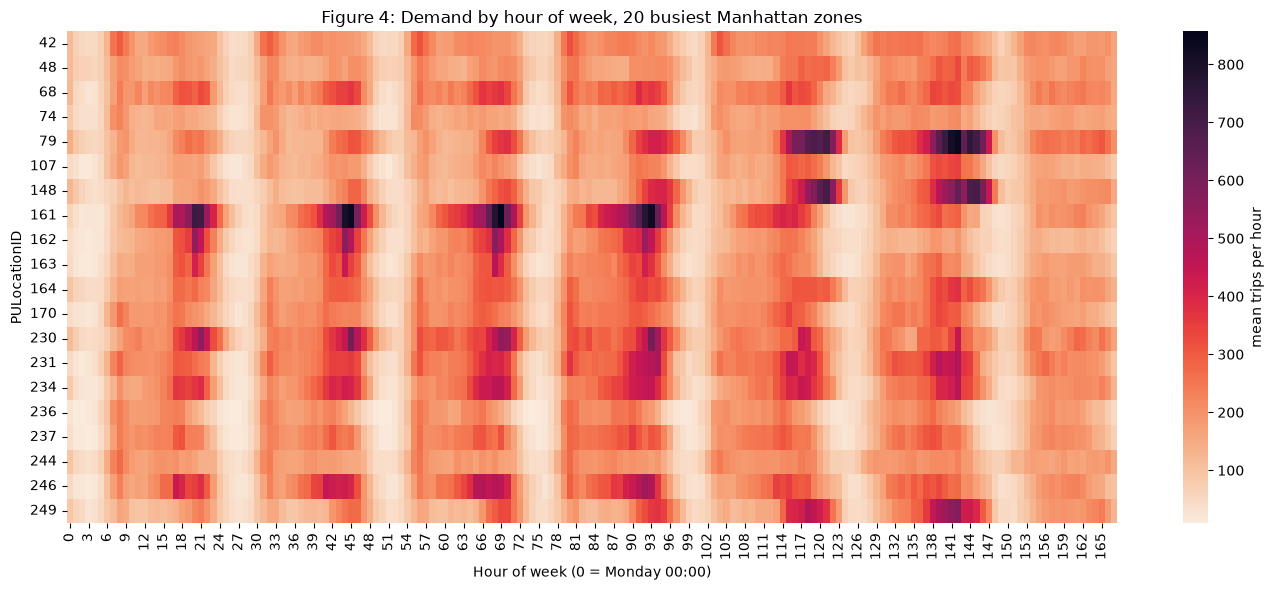

In [3]:
pivot = cells.pivot_table(index="PULocationID", columns="how", values="D", aggfunc="mean")

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot, cmap="rocket_r", ax=ax, cbar_kws={"label": "mean trips per hour"})
ax.set_xlabel("Hour of week (0 = Monday 00:00)")
ax.set_ylabel("PULocationID")
ax.set_title("Figure 4: Demand by hour of week, 20 busiest Manhattan zones")
plt.tight_layout()
plt.savefig("../reports/figures/fig4_demand_heatmap.png", dpi=150)
plt.show()

## B2. Interference simulation, semi-synthetic

**Assumptions:**
- **Demand:** `D` in each cell is the real Uber trip count. Completed trips stand in
  for requests, which understates true demand.
- **Supply capacity:** `S` for each cell is the 80th percentile of `D` for that zone
  and hour-of-week across the month. This makes the busiest hours supply-constrained,
  matching the real platform.
- **Matching:** completed trips = min(demand, S). When demand exceeds supply, every
  request has the same chance of being matched, p = S / demand.
- **Treatment:** treated riders request `(1 + L)` times as many trips, L = 0.10.

In [4]:
L = 0.10
cells = add_supply_cap(cells, quantile=0.8)
gte = ground_truth_effect(cells, L)
print(f"Ground truth global treatment effect (everyone treated vs nobody treated): {gte:.4%}")

Ground truth global treatment effect (everyone treated vs nobody treated): 5.0863%


In [5]:
n_reps = 300
rng = np.random.default_rng(0)

rider_ab_estimates = []
for _ in range(n_reps):
    est, *_ = rider_ab_once(cells, L, rng)
    rider_ab_estimates.append(est)
rider_ab_estimates = np.array(rider_ab_estimates)

switchback_estimates = []
for _ in range(n_reps):
    est = switchback_once(cells, L, rng, block_h=2)
    switchback_estimates.append(est)
switchback_estimates = np.array(switchback_estimates)

print(f"Rider-level A/B:  mean={rider_ab_estimates.mean():.4%}, sd={rider_ab_estimates.std(ddof=1):.4%}")
print(f"Switchback (2h):  mean={switchback_estimates.mean():.4%}, sd={switchback_estimates.std(ddof=1):.4%}")
print(f"Ground truth:     {gte:.4%}")
print(f"Rider-level A/B bias vs ground truth:  {rider_ab_estimates.mean() - gte:.4%}")
print(f"Switchback bias vs ground truth:       {switchback_estimates.mean() - gte:.4%}")

Rider-level A/B:  mean=9.9879%, sd=0.1289%
Switchback (2h):  mean=5.1999%, sd=0.9382%
Ground truth:     5.0863%
Rider-level A/B bias vs ground truth:  4.9016%
Switchback bias vs ground truth:       0.1136%


**Figure 5: histograms of rider-level A/B and switchback estimates, vertical line at ground truth.**

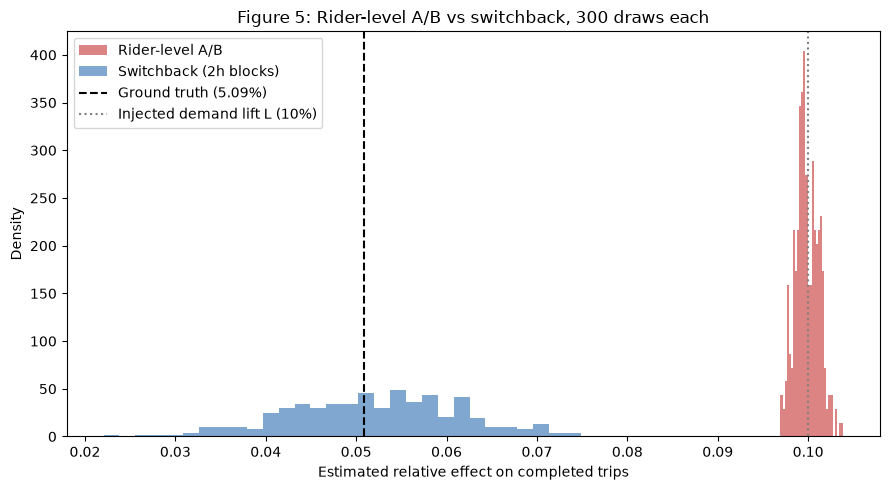

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(rider_ab_estimates, bins=30, alpha=0.6, label="Rider-level A/B", color="#c53030", density=True)
ax.hist(switchback_estimates, bins=30, alpha=0.6, label="Switchback (2h blocks)", color="#2b6cb0", density=True)
ax.axvline(gte, color="black", linestyle="--", linewidth=1.5, label=f"Ground truth ({gte:.2%})")
ax.axvline(L, color="gray", linestyle=":", linewidth=1.5, label=f"Injected demand lift L ({L:.0%})")
ax.set_xlabel("Estimated relative effect on completed trips")
ax.set_ylabel("Density")
ax.set_title("Figure 5: Rider-level A/B vs switchback, 300 draws each")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/fig5_bias_variance.png", dpi=150)
plt.show()

**Expected pattern:** the rider-level A/B should land near the injected demand lift
L (10%) regardless of supply tightness, while the true effect on *completed* trips is
smaller because peak hours can't serve the extra demand. The switchback should be
centered close to the ground truth but with a wider spread — the bias/variance
trade-off that's the core point of this exercise.

### Harm to control riders (SUTVA violation in the rider-level A/B)

In [7]:
all_control_match_rate = np.minimum(cells.D, cells.S).sum() / cells.D.sum()

control_match_rates = []
rng_h = np.random.default_rng(1)
for _ in range(n_reps):
    _, comp_t, comp_c, dem_t, dem_c = rider_ab_once(cells, L, rng_h)
    control_match_rates.append(comp_c / dem_c)
control_match_rates = np.array(control_match_rates)

print(f"Control riders' match rate in an all-control world: {all_control_match_rate:.4%}")
print(f"Control riders' match rate when sharing supply with treated riders (rider-level A/B): "
      f"{control_match_rates.mean():.4%}")
print(f"Drop in control match rate caused by the treatment group: "
      f"{all_control_match_rate - control_match_rates.mean():.4%}")

Control riders' match rate in an all-control world: 98.3591%
Control riders' match rate when sharing supply with treated riders (rider-level A/B): 95.6777%
Drop in control match rate caused by the treatment group: 2.6814%


### Sensitivity check: supply tightness

In [8]:
n_reps_sens = 150
rows = []
for q in [0.70, 0.80, 0.90]:
    cells_q = add_supply_cap(cells.drop(columns=["S"]), quantile=q)
    gte_q = ground_truth_effect(cells_q, L)
    rng_q = np.random.default_rng(hash(("sens", q)) % (2**32))
    ests_q = np.array([rider_ab_once(cells_q, L, rng_q)[0] for _ in range(n_reps_sens)])
    rows.append({
        "supply_percentile": q, "ground_truth": gte_q,
        "rider_ab_mean": ests_q.mean(), "bias": ests_q.mean() - gte_q,
    })

sensitivity = pd.DataFrame(rows)
sensitivity

,supply_percentile,ground_truth,rider_ab_mean,bias
0,0.7,0.0399,0.1000,0.0601
1,0.8,0.0509,0.0999,0.0490
2,0.9,0.0586,0.1001,0.0414


## B3. Choosing a switchback block length from real wait-time data

This section uses **only real data, no injected effect** — a switchback A/A test on
the real `wait` series. For block lengths of 1, 2 and 4 hours, cells are randomly
assigned to arms 500 times; each time, the difference in mean wait is estimated with
`wait ~ T + C(PULocationID) + C(how)`.

In [9]:
trip_wait_var = trips.wait_min.var(ddof=1)
print(f"Trip-level wait variance (naive-SE input): {trip_wait_var:.4f} min^2")

n_reps_b3 = 500
block_lengths = [1, 2, 4]
b3_rows = []

for bh in block_lengths:
    rng_b3 = np.random.default_rng(1000 + bh)
    estimates, naive_ses = [], []
    for _ in range(n_reps_b3):
        est, naive_se, n_t, n_c = aa_block_length_once(cells, rng_b3, bh, trip_wait_var)
        estimates.append(est)
        naive_ses.append(naive_se)
    estimates = np.array(estimates)
    naive_ses = np.array(naive_ses)

    empirical_se = estimates.std(ddof=1)
    mde_sec = 2.8 * empirical_se * 60
    se_ratio = empirical_se / naive_ses.mean()
    naive_fpr = np.mean(np.abs(estimates / naive_ses) > 1.96)

    b3_rows.append({
        "block_h": bh,
        "empirical_se_min": empirical_se,
        "naive_se_min": naive_ses.mean(),
        "se_ratio_emp_over_naive": se_ratio,
        "mde_seconds": mde_sec,
        "naive_fpr": naive_fpr,
    })

b3 = pd.DataFrame(b3_rows)
b3

Trip-level wait variance (naive-SE input): 10.1651 min^2


,block_h,empirical_se_min,naive_se_min,se_ratio_emp_over_naive,mde_seconds,naive_fpr
0,1,0.0115,0.0038,3.0170,1.9374,0.516
1,2,0.0149,0.0038,3.9104,2.5112,0.586
2,4,0.0174,0.0038,4.5437,2.9182,0.676


**Figure 6: MDE vs block length, with the naive-SE false-positive rate alongside.**

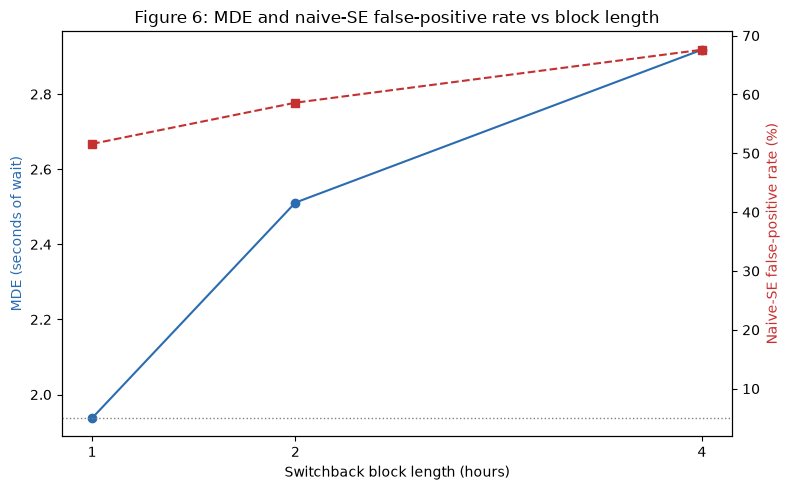

In [10]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(b3.block_h, b3.mde_seconds, "o-", color="#2b6cb0", label="MDE (seconds)")
ax1.set_xlabel("Switchback block length (hours)")
ax1.set_ylabel("MDE (seconds of wait)", color="#2b6cb0")
ax1.set_xticks(block_lengths)

ax2 = ax1.twinx()
ax2.plot(b3.block_h, b3.naive_fpr * 100, "s--", color="#c53030", label="Naive-SE false-positive rate")
ax2.axhline(5, color="gray", linestyle=":", linewidth=1)
ax2.set_ylabel("Naive-SE false-positive rate (%)", color="#c53030")

ax1.set_title("Figure 6: MDE and naive-SE false-positive rate vs block length")
fig.tight_layout()
plt.savefig("../reports/figures/fig6_block_length.png", dpi=150)
plt.show()

**Trade-off:**
- **Longer blocks:** less carryover (driver positions and queues from the previous
  block have more time to settle), but fewer independent units, so the MDE grows.
- **Shorter blocks:** more power, but more contamination from carryover.
- **Common mitigations:** drop the first 15 to 30 minutes after each switch as a
  burn-in period, and randomize at the city-time level when zones affect each other.
- **Limitations stated honestly:** spillovers between neighboring zones are ignored,
  and hourly data can't model carryover within an hour.

In [11]:
cells.to_parquet("../data/cells_with_supply.parquet")
sensitivity.to_csv("../reports/figures/part_b_sensitivity_table.csv", index=False)
b3.to_csv("../reports/figures/part_b_block_length_table.csv", index=False)
print("Saved cells, sensitivity table, and block-length table.")

Saved cells, sensitivity table, and block-length table.
